# Attention from scratch

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/1_foundations/06_attention_from_scratch.ipynb) &nbsp; Guide note: [guide-attention](https://www.matthewwnuk.com/guide-attention.html)

Attention is one operation, and every variant in the guide is a change to where its inputs come from
or to its mask. This notebook builds it up in small steps: the formula, why it is scaled, masks, heads,
what it costs, and finally the linear form that turns it into a recurrence with a fixed-size memory.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import time, numpy as np, torch, torch.nn.functional as F, matplotlib.pyplot as plt
from guide_utils import style
style.use(); torch.manual_seed(0)

## The formula in four lines

Scores are dot products of queries with keys. A softmax turns each row of scores into weights that sum
to one. The output is the weighted average of the values.

In [3]:
def attention(q, k, v, mask=None):
    scores = q @ k.transpose(-2, -1) / k.shape[-1] ** 0.5            # (n_q, n_k)
    if mask is not None: scores = scores.masked_fill(~mask, float("-inf"))
    weights = scores.softmax(-1)
    return weights @ v, weights

n, d = 6, 16; q, k, v = torch.randn(n, d), torch.randn(n, d), torch.randn(n, d)
out, w = attention(q, k, v)
print("rows of the weight matrix sum to", w.sum(-1).numpy().round(3))
print("matches PyTorch:", torch.allclose(out, F.scaled_dot_product_attention(q[None], k[None], v[None])[0], atol=1e-6))

rows of the weight matrix sum to [1. 1. 1. 1. 1. 1.]
matches PyTorch: True


## Why divide by the square root of the width

The dot product of two random vectors of width d has a typical size of sqrt(d). Without the division,
wide vectors give large scores, the softmax puts nearly all its weight on one token, and its gradient
vanishes. Measure the largest weight in each row with and without the scaling.

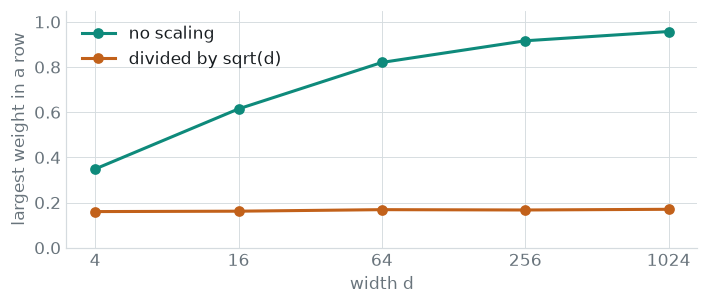

In [4]:
ds = [4, 16, 64, 256, 1024]; with_s, without = [], []
for d_ in ds:
    q_, k_ = torch.randn(200, d_), torch.randn(32, d_); s = q_ @ k_.T
    without.append(s.softmax(-1).max(-1).values.mean().item()); with_s.append((s / d_ ** 0.5).softmax(-1).max(-1).values.mean().item())
plt.figure(figsize=(7.4, 2.8)); plt.plot(ds, without, marker="o", label="no scaling"); plt.plot(ds, with_s, marker="o", label="divided by sqrt(d)")
plt.xscale("log", base=2); plt.xticks(ds, ds); plt.xlabel("width d"); plt.ylabel("largest weight in a row"); plt.ylim(0, 1.05); plt.legend(); plt.show()

## Masks

A mask says which tokens may look at which. A causal mask lets a token see only itself and earlier
tokens, which is what makes next-token prediction possible.

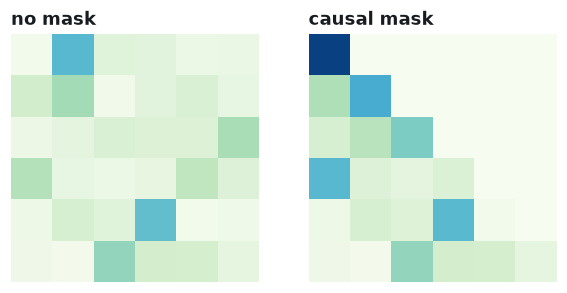

changing the last token changes earlier outputs by 0.0


In [5]:
causal = torch.tril(torch.ones(n, n, dtype=torch.bool)); _, wc = attention(q, k, v, causal)
fig, ax = plt.subplots(1, 2, figsize=(6.4, 3)); ax[0].imshow(w, cmap="GnBu", vmin=0, vmax=1); ax[0].set_title("no mask"); ax[1].imshow(wc, cmap="GnBu", vmin=0, vmax=1); ax[1].set_title("causal mask")
for a in ax: style.bare(a)
plt.show()
x = torch.randn(n, d); o1, _ = attention(x, x, x, causal); x2 = x.clone(); x2[-1] += 5.0; o2, _ = attention(x2, x2, x2, causal)
print("changing the last token changes earlier outputs by", (o1[:-1] - o2[:-1]).abs().max().item())

## Heads

Split the width into h slices, run attention in each, and join the results. The cost is about the same
as one wide head, and each slice can follow a different relationship.

In [6]:
def multi_head(x, Wq, Wk, Wv, Wo, heads):
    n_, d_ = x.shape; split = lambda t: t.reshape(n_, heads, d_ // heads).transpose(0, 1)        # (heads, n, d / heads)
    out, wts = attention(split(x @ Wq), split(x @ Wk), split(x @ Wv))
    return out.transpose(0, 1).reshape(n_, d_) @ Wo, wts
d, heads = 32, 4; x = torch.randn(n, d); Ws = [torch.randn(d, d) / d ** 0.5 for _ in range(4)]
out, wts = multi_head(x, *Ws, heads); print("output", tuple(out.shape), " weights", tuple(wts.shape), "= heads x tokens x tokens")
mha = torch.nn.MultiheadAttention(d, heads, bias=False, batch_first=True)
with torch.no_grad(): mha.in_proj_weight.copy_(torch.cat([W.T for W in Ws[:3]])); mha.out_proj.weight.copy_(Ws[3].T)
print("matches torch.nn.MultiheadAttention:", torch.allclose(out, mha(x[None], x[None], x[None])[0][0], atol=1e-5))

output (6, 32)  weights (4, 6, 6) = heads x tokens x tokens
matches torch.nn.MultiheadAttention: True


## What it costs

The score table has n x n entries, so time grows with the square of the sequence length.

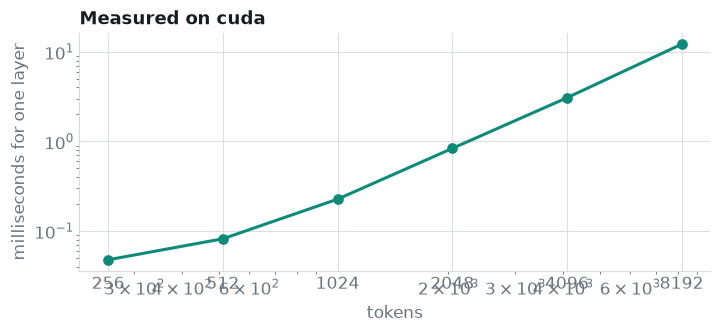

doubling the tokens multiplies the time by [1.7, 2.8, 3.7, 3.7, 4.0]


In [7]:
dev = "cuda" if torch.cuda.is_available() else "cpu"; ns = [256, 512, 1024, 2048, 4096] + ([8192] if dev == "cuda" else []); ms = []
for n_ in ns:
    a = torch.randn(1, 8, n_, 64, device=dev); t = []
    for _ in range(8):
        if dev == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter(); F.scaled_dot_product_attention(a, a, a)
        if dev == "cuda": torch.cuda.synchronize()
        t.append((time.perf_counter() - t0) * 1000)
    ms.append(sorted(t[2:])[len(t[2:]) // 2])
plt.figure(figsize=(7.4, 2.8)); plt.loglog(ns, ms, marker="o"); plt.xticks(ns, ns); plt.xlabel("tokens"); plt.ylabel("milliseconds for one layer"); plt.title(f"Measured on {dev}"); plt.show()
print("doubling the tokens multiplies the time by", [round(ms[i + 1] / ms[i], 1) for i in range(len(ms) - 1)])

## Linear attention: the same lookup as a recurrence

Drop the softmax and the sums can be reordered. Instead of comparing every query with every key, add up
value-times-key once into a d x d matrix S, and answer each query with S @ q. With a causal mask, S
becomes a running sum, which is a recurrent network with a fixed-size state.

In [8]:
n, d = 50, 16; q, k, v = torch.randn(n, d), torch.randn(n, d), torch.randn(n, d)
table = (q @ k.T) @ v                                   # the n x n way, no softmax
S = v.T @ k; fast = q @ S.T                             # the d x d way
print("same answer both ways:", torch.allclose(table, fast, atol=1e-4))
S = torch.zeros(d, d); causal_out = []
for t in range(n):
    S = S + torch.outer(v[t], k[t]); causal_out.append(S @ q[t])           # write, then read
print("recurrence matches masked attention:", torch.allclose(torch.stack(causal_out), (torch.tril(torch.ones(n, n)) * (q @ k.T)) @ v, atol=1e-4))

same answer both ways: True
recurrence matches masked attention: True


## A fixed-size memory: adding against the delta rule

S is an associative memory: write a (key, value) pair by adding their outer product, read by multiplying
with a query. Adding has a flaw. Write a new value under a key that is already stored and a read returns
a mixture of old and new. The delta rule first removes what the memory currently returns for that key.

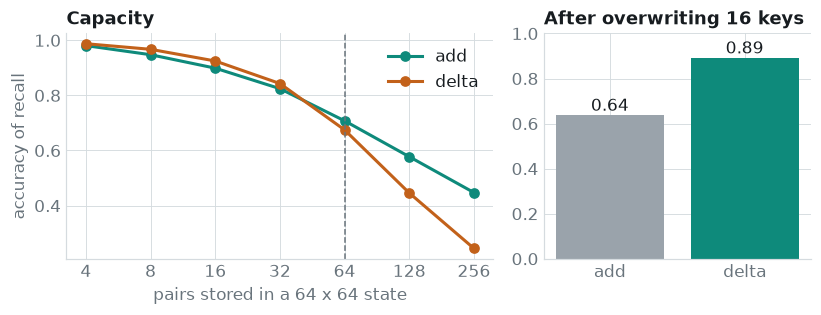

In [9]:
def write(S, k, v, rule):
    return S + torch.outer(v, k) if rule == "add" else S + torch.outer(v - S @ k, k)

def recall(rule, n_pairs, overwrite=False, d=64, trials=30):
    sims = []
    for _ in range(trials):
        K = F.normalize(torch.randn(n_pairs, d), dim=-1); V1, V2 = torch.randn(n_pairs, d), torch.randn(n_pairs, d); S = torch.zeros(d, d)
        for k_, v_ in zip(K, V1): S = write(S, k_, v_, rule)
        target = V1
        if overwrite:
            for k_, v_ in zip(K, V2): S = write(S, k_, v_, rule)
            target = V2
        sims.append(F.cosine_similarity(K @ S.T, target, dim=-1).mean().item())
    return np.mean(sims)

counts = [4, 8, 16, 32, 64, 128, 256]; fig, ax = plt.subplots(1, 2, figsize=(7.6, 3), gridspec_kw=dict(width_ratios=[1.6, 1]))
for rule in ("add", "delta"): ax[0].plot(counts, [recall(rule, c) for c in counts], marker="o", label=rule)
ax[0].axvline(64, color=style.MUTED, ls="--", lw=1); ax[0].set_xscale("log", base=2); ax[0].set_xticks(counts); ax[0].set_xticklabels(counts); ax[0].set_xlabel("pairs stored in a 64 x 64 state"); ax[0].set_ylabel("accuracy of recall"); ax[0].legend(); ax[0].set_title("Capacity")
ow = [recall(r, 16, overwrite=True) for r in ("add", "delta")]; ax[1].bar(["add", "delta"], ow, color=[style.GREY, style.TEAL]); ax[1].set_ylim(0, 1); ax[1].set_title("After overwriting 16 keys")
for i, val in enumerate(ow): ax[1].text(i, val + 0.02, f"{val:.2f}", ha="center")
plt.tight_layout(); plt.show()

The delta rule does not add capacity. Its advantage is the right-hand panel: when stored keys are given
new values, it replaces the old ones where plain addition blends them. Gated DeltaNet adds one more
learned number per token that scales the whole state, so the model can also forget.

## Things to try

- Add a gate: multiply `S` by 0.97 before each write, and plot recall against how long ago a pair was written.
- Give the causal mask a window, so each token sees only the previous eight. What changes in the cost?
- Replace the softmax in `attention` with a sigmoid. What breaks?